\# 🪖 Helmet / PPE Detection using YOLOv8

**Name:** Abdul Rafay Awan| **Roll No:** 822651 | **Course:** Computer Vision

**Problem:** Failing to wear helmets at construction sites and roads leads to serious injuries. In this project, a YOLOv8 object detection model is trained to detect helmets and non-helmet instances in images.



In [1]:
!pip install -q ultralytics gradio
import glob, random, pandas as pd, matplotlib.pyplot as plt, matplotlib.image as mpimg
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset
import torch
print('GPU:', torch.cuda.is_available())

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 5.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU: True


In [2]:
OPTION = "ultralytics"

if OPTION == "ultralytics":
    DATA_YAML = "construction-ppe.yaml"
else:
    !pip install -q roboflow
    from roboflow import Roboflow
    rf = Roboflow(api_key="YOUR_API_KEY")
    ds = rf.workspace("YOUR_WORKSPACE").project("YOUR_PROJECT").version(1).download("yolov8")
    DATA_YAML = ds.location + "/data.yaml"

info = check_det_dataset(DATA_YAML)
print("Classes:", info['names'])
print("Train:", info['train']); print("Val:", info['val'])


WARNING ⚠️ Dataset 'construction-ppe.yaml' images not found, missing path '/content/datasets/construction-ppe/images/val'
Unzipping /content/datasets/construction-ppe.zip to /content/datasets/construction-ppe...: 100% ━━━━━━━━━━━━ 2852/2852 2.3Kfiles/s 1.2s
Dataset download success ✅ (3.2s), saved to /content/datasets

Classes: {0: 'helmet', 1: 'gloves', 2: 'vest', 3: 'boots', 4: 'goggles', 5: 'none', 6: 'Person', 7: 'no_helmet', 8: 'no_goggle', 9: 'no_gloves', 10: 'no_boots'}
Train: /content/datasets/construction-ppe/images/train
Val: /content/datasets/construction-ppe/images/val


Validation images: 123


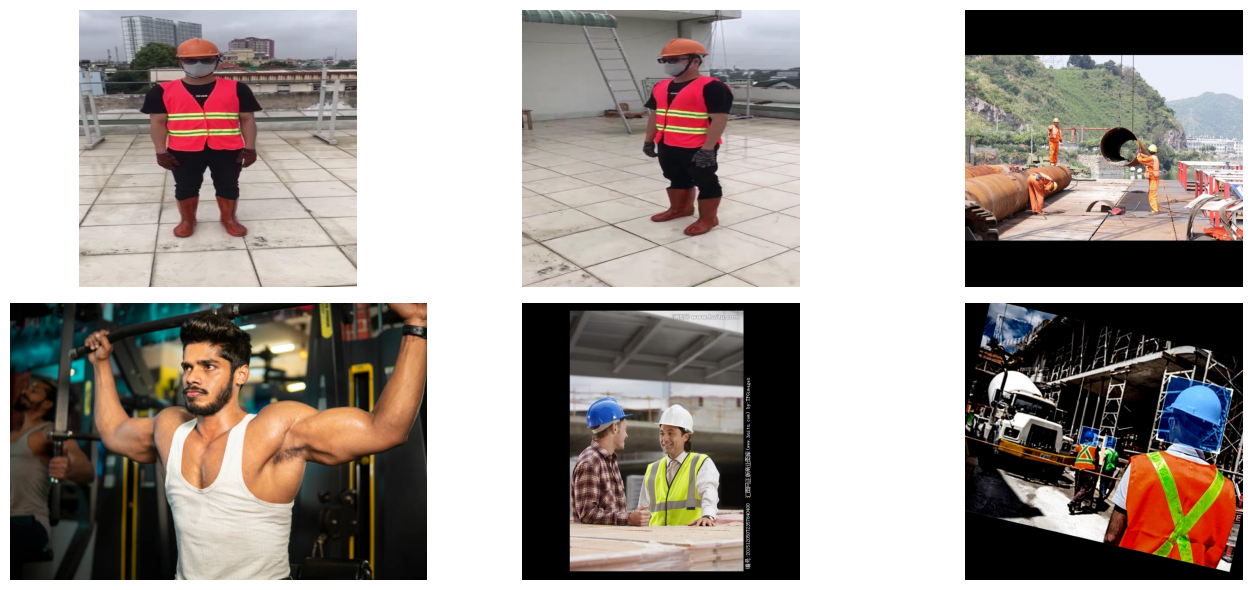

In [3]:
val_imgs = glob.glob(str(info['val']) + '/**/*.jpg', recursive=True) + glob.glob(str(info['val']) + '/**/*.png', recursive=True)
print("Validation images:", len(val_imgs))
plt.figure(figsize=(14, 6))
for i, p in enumerate(random.sample(val_imgs, 6)):
    plt.subplot(2, 3, i+1); plt.imshow(mpimg.imread(p)); plt.axis('off')
plt.tight_layout(); plt.show()

In [4]:
model = YOLO('yolov8s.pt')
model.train(data=DATA_YAML, epochs=30, imgsz=640, batch=16, patience=10,
            project='runs', name='helmet', seed=42, plots=True)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=construction-ppe.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=helmet, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x785f9e9ab690>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

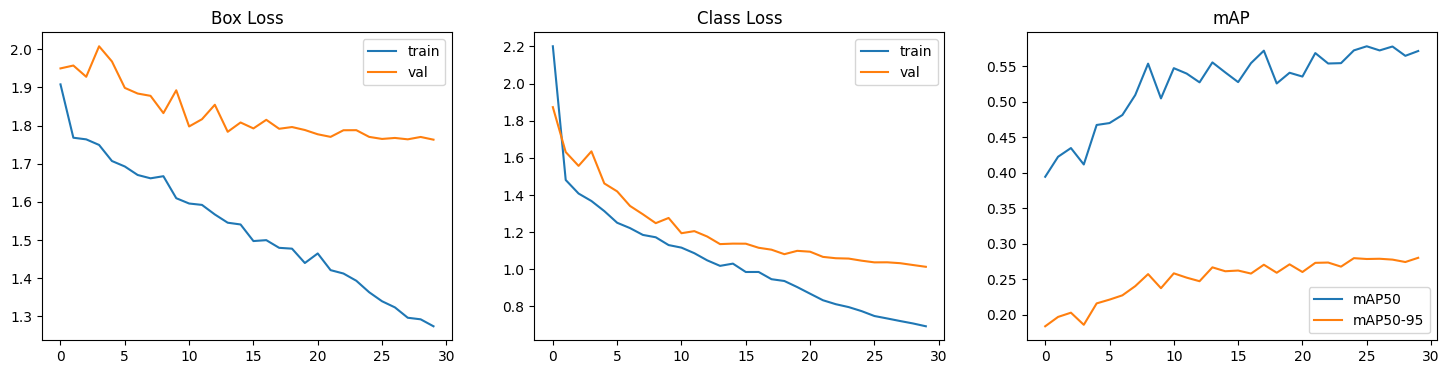

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,129,841 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1201.6±552.0 MB/s, size: 80.5 KB)
val: Scanning /content/datasets/construction-ppe/labels/val.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 26.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.7it/s 5.2s
                   all        143       1172      0.648      0.575      0.573      0.277
                helmet        107        201      0.812      0.836      0.826      0.432
                gloves         68        136      0.816      0.801      0.839      0.384
                  vest        109        171      0.799      0.836      0.845      0.526
                 boots         64        151      0.641      0.762      0.787      0.438
               goggles         4

In [7]:
RUN = model.trainer.save_dir
df = pd.read_csv(f'{RUN}/results.csv'); df.columns = df.columns.str.strip()
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(df['train/box_loss'], label='train'); ax[0].plot(df['val/box_loss'], label='val'); ax[0].set_title('Box Loss'); ax[0].legend()
ax[1].plot(df['train/cls_loss'], label='train'); ax[1].plot(df['val/cls_loss'], label='val'); ax[1].set_title('Class Loss'); ax[1].legend()
ax[2].plot(df['metrics/mAP50(B)'], label='mAP50'); ax[2].plot(df['metrics/mAP50-95(B)'], label='mAP50-95'); ax[2].set_title('mAP'); ax[2].legend()
plt.show()

best = YOLO(f'{RUN}/weights/best.pt')
m = best.val(data=DATA_YAML)
print(f'Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | mAP@50 {m.box.map50:.3f} | mAP@50-95 {m.box.map:.3f}')

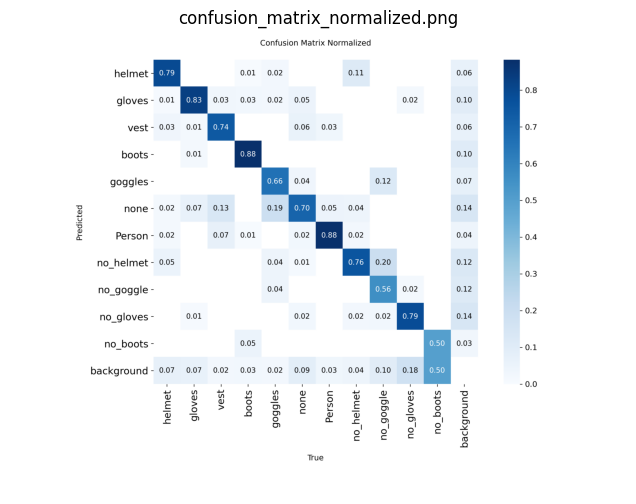

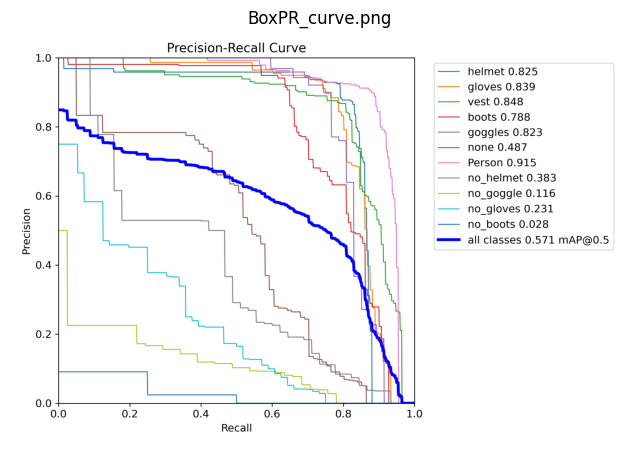

In [9]:
import os

for f in ['confusion_matrix_normalized.png', 'PR_curve.png', 'BoxPR_curve.png']:
    img_path = f'{RUN}/{f}'
    if os.path.exists(img_path):
        plt.figure(figsize=(8, 6))
        plt.imshow(mpimg.imread(img_path))
        plt.axis('off')
        plt.title(f)
        plt.show()

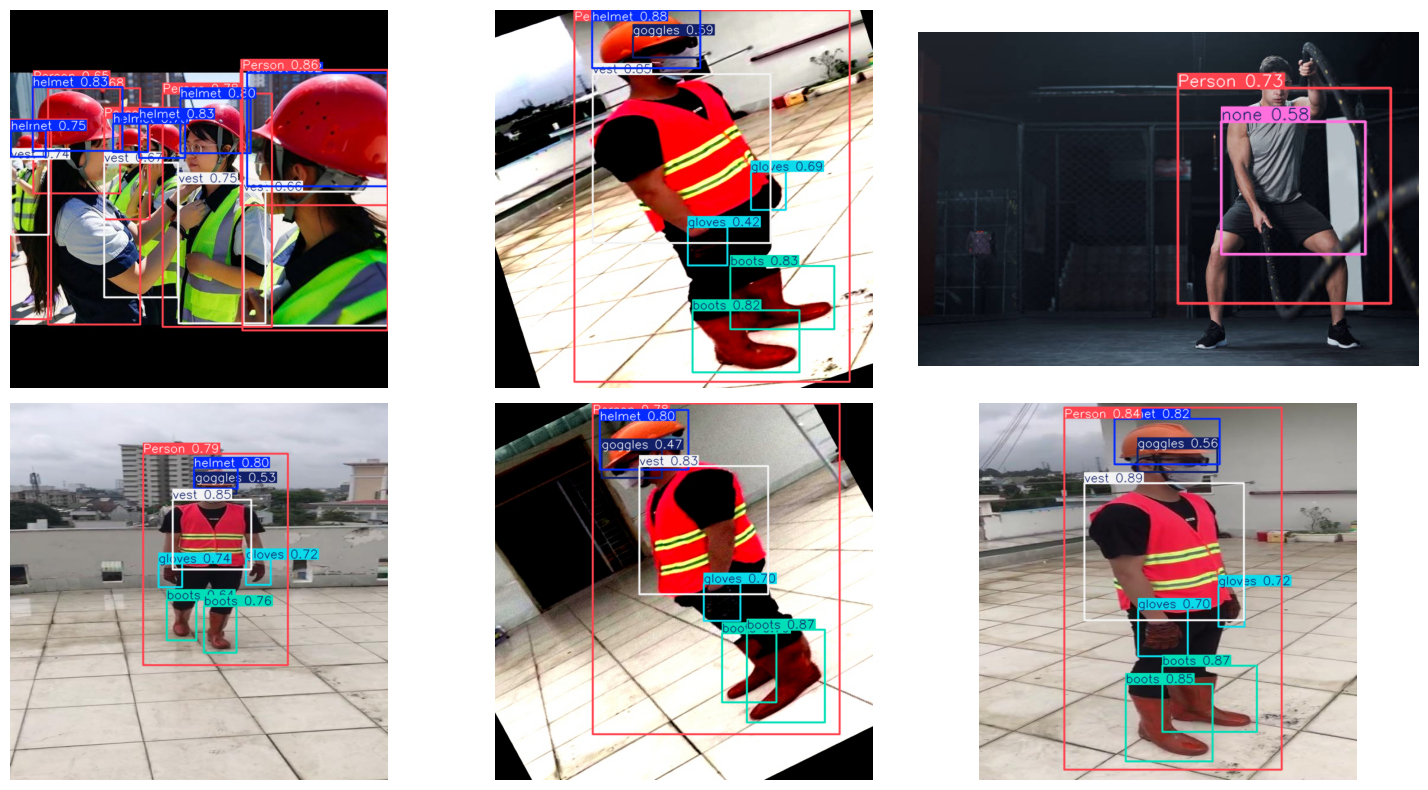

In [10]:
plt.figure(figsize=(15, 8))
for i, p in enumerate(random.sample(val_imgs, 6)):
    r = best.predict(p, conf=0.4, verbose=False)[0]
    plt.subplot(2, 3, i+1); plt.imshow(r.plot()[..., ::-1]); plt.axis('off')
plt.tight_layout(); plt.show()

In [12]:
from google.colab import files
files.download(f'{RUN}/weights/best.pt')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
import gradio as gr
def detect(img, conf):
    return best.predict(img, conf=conf, verbose=False)[0].plot()[..., ::-1]
gr.Interface(detect,
    [gr.Image(type='numpy'), gr.Slider(0.1, 0.9, 0.4, label='Confidence')],
    gr.Image(), title='Helmet / PPE Detection').launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://4fe25b329ae220c463.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.



KeyboardInterrupt

